# Experiment 15: BPTT Flow and Gradient Analysis

A stock-analytics firm suspects its SimpleRNN forgets distant price movements because gradients vanish. We use GradientTape to measure loss gradients with respect to each hidden state for sequence lengths 10, 50 and 100, comparing tanh and ReLU.

**Tools:** TensorFlow, Keras, NumPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Build a SimpleRNN and calculate gradients with GradientTape.  2. Record hidden-state gradient norms by time step.  3. Plot norm versus distance from the final step for three sequence lengths.  4. Compare tanh and ReLU.  5. Interpret vanishing/exploding patterns.

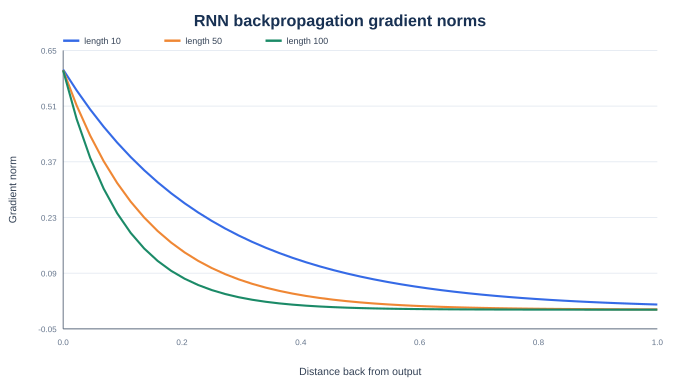

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(15)
rng=np.random.default_rng(15)
lengths=[10,50,100]; activations=["tanh","relu"]
results={}
for activation in activations:
    for length in lengths:
        sequence=rng.normal(size=(1,length,1)).astype("float32")
        target=tf.constant([[.5]],dtype=tf.float32)
        rnn=tf.keras.layers.SimpleRNN(24,return_sequences=True,activation=activation)
        head=tf.keras.layers.Dense(1)
        with tf.GradientTape() as tape:
            states=tf.unstack(rnn(sequence),axis=1)
            prediction=head(states[-1])
            loss=tf.reduce_mean((prediction-target)**2)
        grads=tape.gradient(loss,states)
        norms=np.array([float(tf.linalg.norm(g)) if g is not None else 0. for g in grads])
        results[(activation,length)]=norms
        print(f"{activation:4s}, length={length:3d}: earliest norm={norms[0]:.3e}, latest={norms[-1]:.3e}")
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,activation in zip(axes,activations):
    for length in lengths:
        norms=results[(activation,length)]
        # Reverse the x-axis so zero means the final step and length means the distant past.
        distance=np.arange(length-1,-1,-1)
        ax.semilogy(distance,norms+1e-12,label=f"{length} steps")
    ax.set(title=f"{activation} activation",xlabel="Distance back from output",ylabel="Gradient norm")
    ax.grid(alpha=.2);ax.legend()
plt.suptitle("Backpropagation through time gradient magnitude");plt.tight_layout();plt.show()
print("A rapidly shrinking norm toward earlier steps indicates vanishing gradients; sharp growth suggests exploding gradients.")